In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("C:/Users/ruxin/Documents/6006 CEM/ecommerce_customer_churn_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (50000, 25)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null 

None

In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,47505.0,37.802968,11.834668,5.00,29.0000,38.000,46.00,200.000000
Membership_Years,50000.0,2.984009,2.059105,0.10,1.4000,2.500,4.00,10.000000
Login_Frequency,50000.0,11.624660,7.810657,0.00,6.0000,11.000,17.00,46.000000
Session_Duration_Avg,46601.0,27.660754,10.871013,1.00,19.7000,26.800,34.70,75.600000
Pages_Per_Session,47000.0,8.737811,3.778220,1.00,6.0000,8.400,11.20,24.100000
Cart_Abandonment_Rate,50000.0,57.079973,16.282723,0.00,46.4000,58.100,68.70,143.743350
Wishlist_Items,46000.0,4.298391,3.189754,0.00,2.0000,4.000,6.00,28.000000
Total_Purchases,50000.0,13.111576,7.017312,-13.00,8.0000,12.000,17.00,128.700000
Average_Order_Value,50000.0,123.117330,175.569714,26.38,87.0500,112.970,144.44,9666.379178
Days_Since_Last_Purchase,47000.0,29.792872,29.695062,0.00,9.0000,21.000,41.00,287.000000


In [3]:
df.isnull().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [4]:
df.duplicated().sum()

0

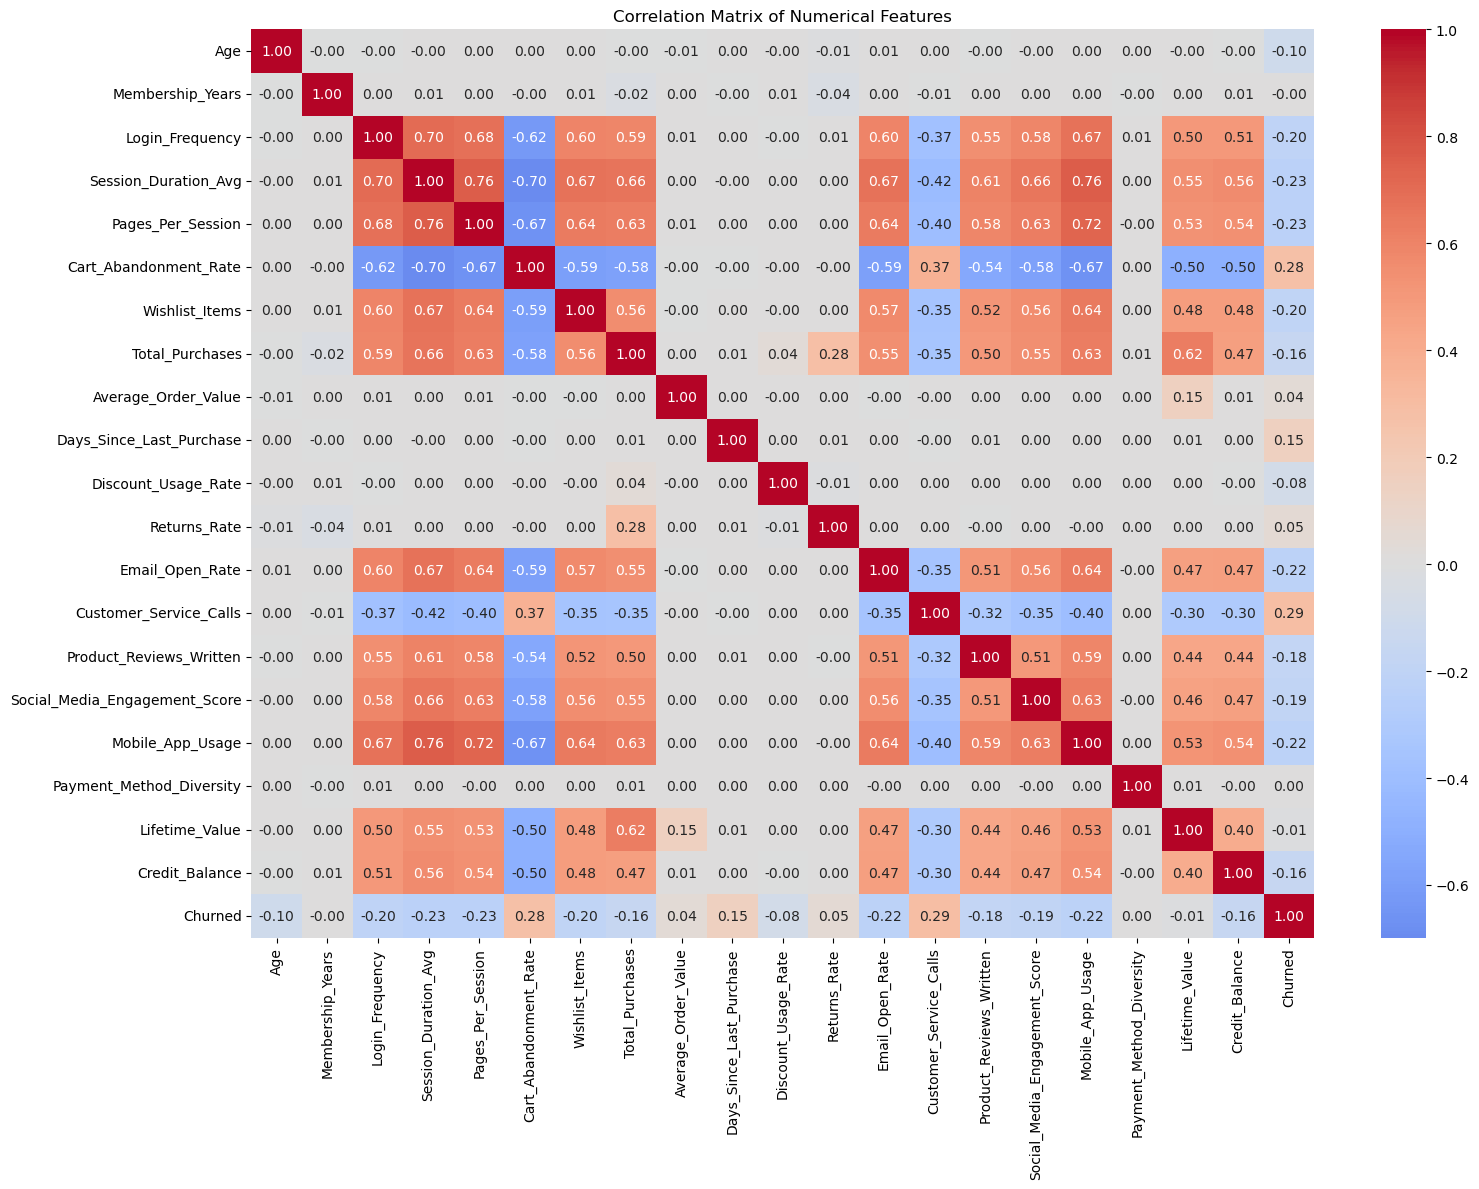

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(16, 12))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [13]:
correlation = numeric_df.corr()["Churned"].drop("Churned")

correlation = correlation.sort_values(
    key=abs,
    ascending=False
)

display(correlation.to_frame(name="Correlation_with_Churned"))

,Correlation_with_Churned
Customer_Service_Calls,0.291103
Cart_Abandonment_Rate,0.277963
Pages_Per_Session,-0.231799
Session_Duration_Avg,-0.228010
Mobile_App_Usage,-0.222876
Email_Open_Rate,-0.222213
Login_Frequency,-0.204379
Wishlist_Items,-0.197708
Social_Media_Engagement_Score,-0.191792
Product_Reviews_Written,-0.181225


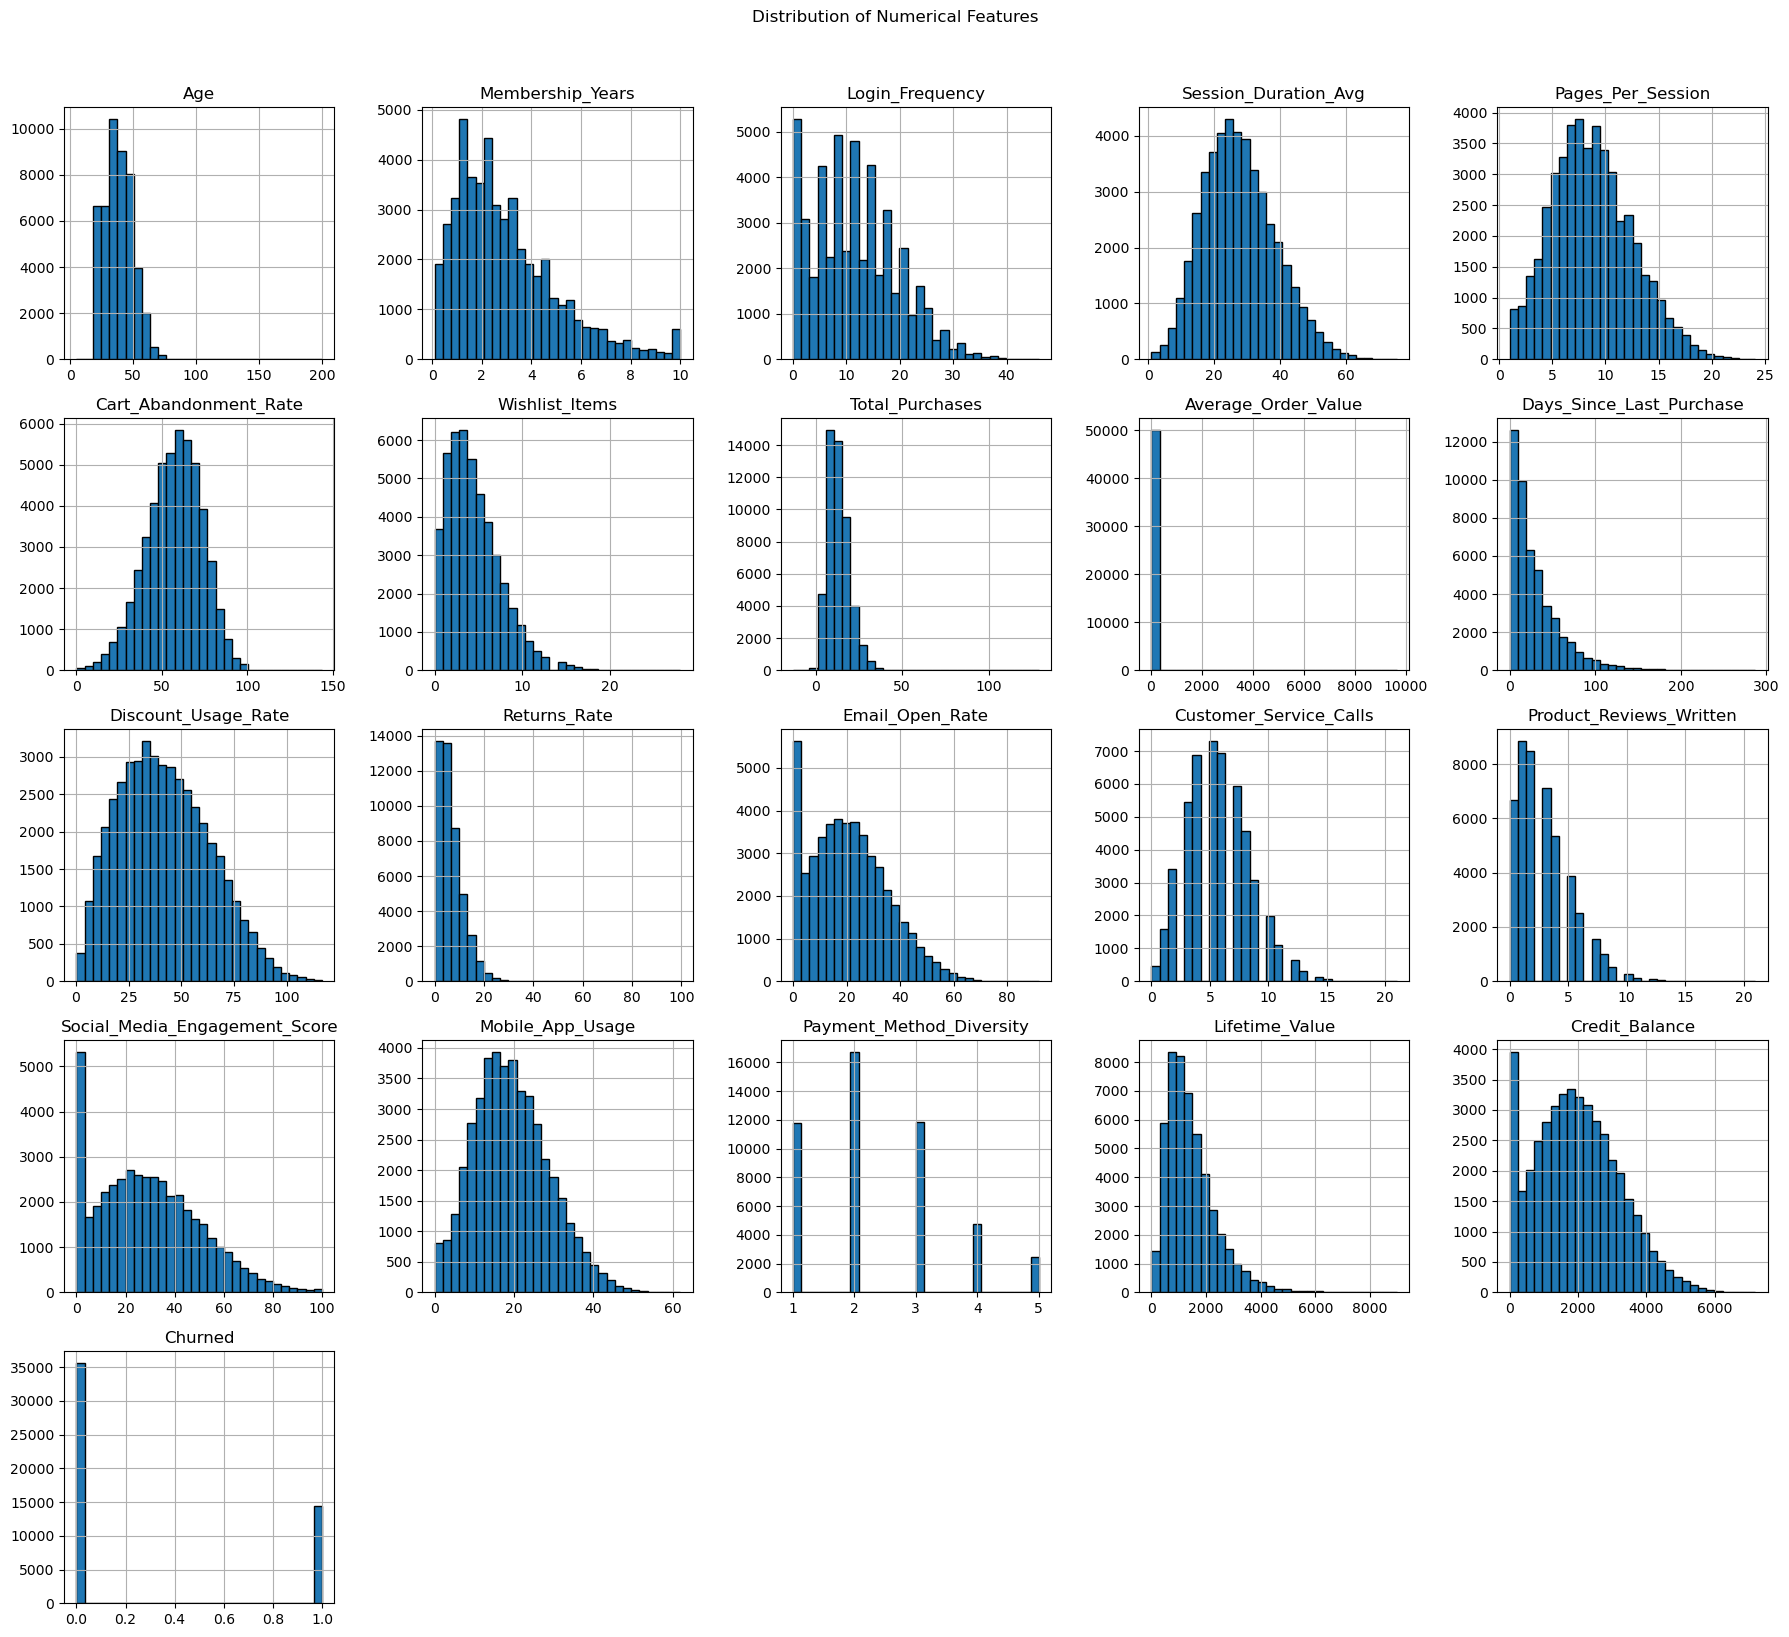

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = df.select_dtypes(include="number").columns

df[numeric_columns].hist(
    figsize=(18, 16),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

In [15]:
numeric_df = df.select_dtypes(include="number")

skewness = numeric_df.skew().sort_values(ascending=False)

skewness_table = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

display(skewness_table.round(3))

,Feature,Skewness
0,Average_Order_Value,42.364
1,Returns_Rate,5.881
2,Total_Purchases,2.690
3,Days_Since_Last_Purchase,1.991
4,Lifetime_Value,1.447
5,Membership_Years,1.137
6,Product_Reviews_Written,1.044
7,Age,0.947
8,Wishlist_Items,0.945
9,Churned,0.931


In [17]:
numeric_df = df.select_dtypes(include="number")

outlier_summary = []

for column in numeric_df.columns:
    Q1 = numeric_df[column].quantile(0.25)
    Q3 = numeric_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (numeric_df[column] < lower_bound) |
        (numeric_df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_table = pd.DataFrame(outlier_summary)

outlier_table = outlier_table.sort_values(
    by="Outlier_Count",
    ascending=False
)

display(outlier_table)

,Feature,Outlier_Count,Outlier_Percentage
17,Payment_Method_Diversity,2439,4.88
9,Days_Since_Last_Purchase,2313,4.63
18,Lifetime_Value,1684,3.37
1,Membership_Years,1581,3.16
11,Returns_Rate,1204,2.41
13,Customer_Service_Calls,1185,2.37
14,Product_Reviews_Written,1090,2.18
8,Average_Order_Value,1005,2.01
6,Wishlist_Items,858,1.72
7,Total_Purchases,628,1.26


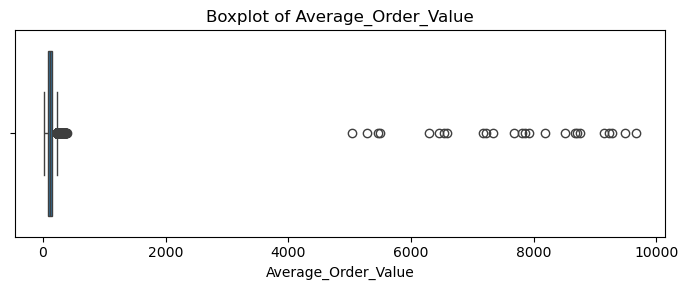

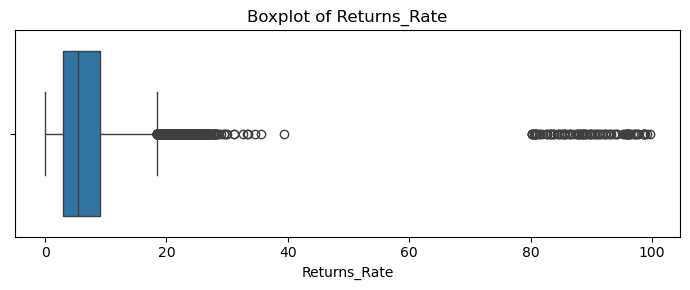

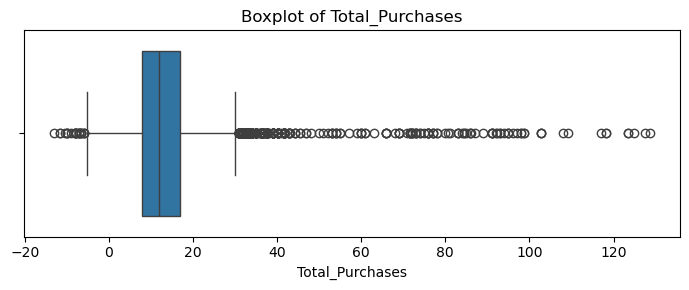

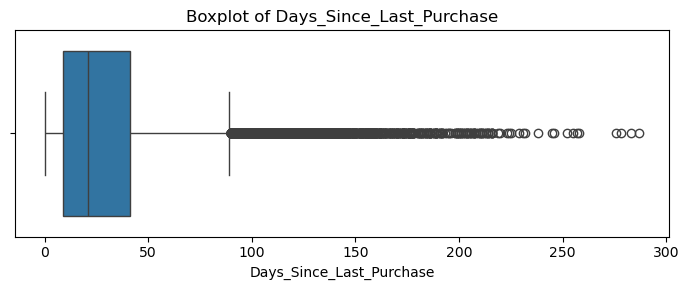

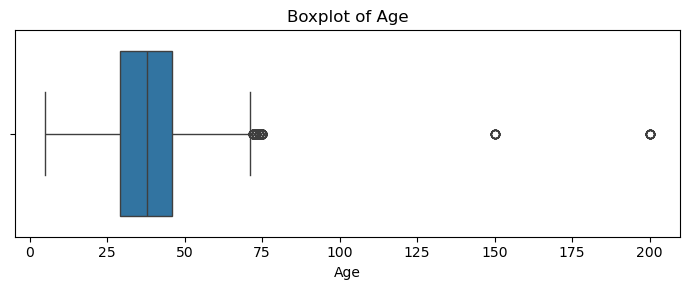

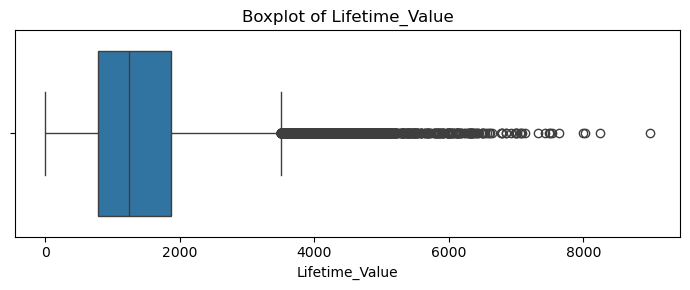

In [18]:
features_to_check = [
    "Average_Order_Value",
    "Returns_Rate",
    "Total_Purchases",
    "Days_Since_Last_Purchase",
    "Age",
    "Lifetime_Value"
]

for column in features_to_check:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

In [19]:
# Count and percentage of each class
class_counts = df["Churned"].value_counts().sort_index()
class_percentages = df["Churned"].value_counts(
    normalize=True
).sort_index() * 100

class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

display(class_table)

,Count,Percentage (%)
Churned,,
0,35550,71.1
1,14450,28.9


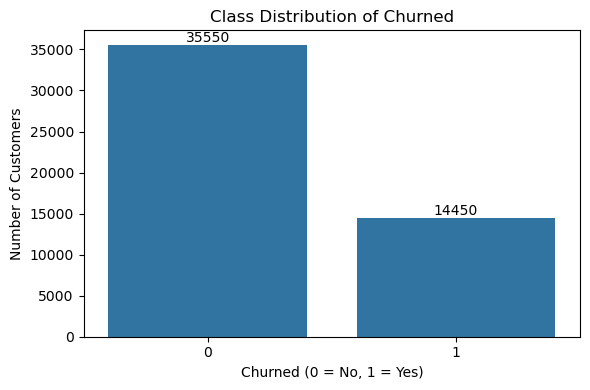

In [20]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x="Churned")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Class Distribution of Churned")
plt.xlabel("Churned (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [21]:
# Check potentially invalid numerical values

checks = {
    "Age below 0 or above 100": 
        ((df["Age"] < 0) | (df["Age"] > 100)).sum(),

    "Negative Total_Purchases": 
        (df["Total_Purchases"] < 0).sum(),

    "Cart_Abandonment_Rate above 100": 
        (df["Cart_Abandonment_Rate"] > 100).sum(),

    "Discount_Usage_Rate above 100": 
        (df["Discount_Usage_Rate"] > 100).sum()
}

for issue, count in checks.items():
    print(f"{issue}: {count}")

Age below 0 or above 100: 20
Negative Total_Purchases: 40
Cart_Abandonment_Rate above 100: 30
Discount_Usage_Rate above 100: 207


In [22]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False))


--- Gender ---
Unique values: 3
Gender
Female    25116
Male      23947
Other       937
Name: count, dtype: int64

--- Country ---
Unique values: 8
Country
USA          17384
UK            7534
Canada        6023
Germany       4925
Australia     4061
France        4013
India         3512
Japan         2548
Name: count, dtype: int64

--- City ---
Unique values: 40
City
Houston        3549
Phoenix        3490
New York       3477
Chicago        3475
Los Angeles    3393
Manchester     1576
Birmingham     1535
Leeds          1529
London         1458
Glasgow        1436
Montreal       1247
Toronto        1209
Calgary        1204
Ottawa         1182
Vancouver      1181
Cologne        1033
Hamburg        1026
Berlin         1013
Munich          960
Frankfurt       893
Lyon            830
Sydney          828
Perth           817
Adelaide        817
Toulouse        815
Melbourne       805
Nice            799
Brisbane        794
Marseille       793
Paris           776
Chennai         736
Bangalore

In [23]:
for column in categorical_columns:
    if df[column].dtype == "object":
        spaces = df[column].dropna().astype(str).ne(
            df[column].dropna().astype(str).str.strip()
        ).sum()

        print(f"{column}: {spaces} values with extra spaces")

Gender: 0 values with extra spaces
Country: 0 values with extra spaces
City: 0 values with extra spaces
Signup_Quarter: 0 values with extra spaces
